# 01 · Atmospheric turbulence: phase screens and frozen flow

Adaptive optics starts with the wavefront error that the atmosphere puts on the telescope pupil. This notebook generates von Kármán phase screens with `phase_screen.py`, checks their statistics against theory, and lets the wind carry them across the pupil.

**Checks against theory:** the aperture variance of many screens against the von Kármán integral (Noll's coefficients in the Kolmogorov limit), and the phase structure function against $6.88\,(r/r_0)^{5/3}$.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
FIGURES = ROOT / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

from phase_screen import (
    fourier_phase_screen,
    frozen_flow_shift,
    phase_to_opd,
    pupil_grid,
    r0_from_seeing,
    scale_r0_with_wavelength,
    von_karman_phase_variance,
    von_karman_structure_function,
)

## 1. From seeing to $r_0$

The Fried parameter $r_0$ is the aperture size over which the turbulent phase varies by about 1 rad RMS. It is linked to the seeing by $\mathrm{FWHM} \approx 0.98\,\lambda / r_0$ and grows as $\lambda^{6/5}$, so the same atmosphere is much gentler in the infrared.

In [2]:
SEEING_ARCSEC = 0.8
r0_500 = r0_from_seeing(SEEING_ARCSEC, wavelength=500e-9)

for band, wavelength in [("V, 500 nm", 500e-9), ("WFS, 750 nm", 750e-9), ("J, 1.25 um", 1.25e-6), ("H, 1.65 um", 1.65e-6), ("K, 2.2 um", 2.2e-6)]:
    r0 = scale_r0_with_wavelength(r0_500, wavelength)
    print(f"{band:12s}  r0 = {r0:5.3f} m   D/r0 for an 8 m telescope = {8.0 / r0:5.1f}")

V, 500 nm     r0 = 0.126 m   D/r0 for an 8 m telescope =  63.3
WFS, 750 nm   r0 = 0.206 m   D/r0 for an 8 m telescope =  38.9
J, 1.25 um    r0 = 0.379 m   D/r0 for an 8 m telescope =  21.1
H, 1.65 um    r0 = 0.529 m   D/r0 for an 8 m telescope =  15.1
K, 2.2 um     r0 = 0.748 m   D/r0 for an 8 m telescope =  10.7


## 2. One phase screen

The screen is a random sum of Fourier modes whose amplitudes follow the von Kármán phase spectrum

$$\Phi(f) = 0.023\, r_0^{-5/3} \left(f^2 + L_0^{-2}\right)^{-11/6}.$$

A plain FFT screen is periodic over its own size and misses most of the large scales, which carry the tip/tilt. `fourier_phase_screen` therefore sums the lowest frequencies explicitly, including subharmonics below the FFT grid. Below: a 2 m pupil, $r_0 = 0.15$ m at 500 nm and $L_0 = 25$ m.

This screen:          7.83 rad RMS = 623 nm
Ensemble expectation: 6.07 rad RMS


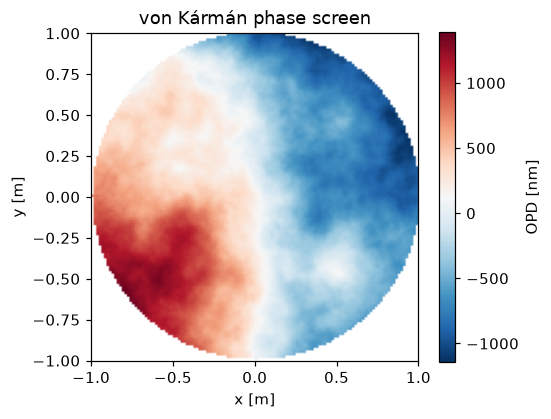

In [3]:
D = 2.0               # pupil diameter [m]
N = 128               # samples across the pupil
DELTA = D / N         # sampling [m]
R0 = 0.15             # Fried parameter at 500 nm [m]
L0 = 25.0             # outer scale [m]
WAVELENGTH = 500e-9   # [m]

phase, X, Y, pupil = fourier_phase_screen(N=N, delta=DELTA, r0=R0, L0=L0, diameter=D, wavelength=WAVELENGTH, seed=1)
expected_rms = np.sqrt(von_karman_phase_variance(D, R0, L0))
print(f"This screen:          {np.nanstd(phase):.2f} rad RMS = {np.nanstd(phase_to_opd(phase, WAVELENGTH)) * 1e9:.0f} nm")
print(f"Ensemble expectation: {expected_rms:.2f} rad RMS")

fig, ax = plt.subplots(figsize=(4.8, 3.9))
image = ax.imshow(phase_to_opd(phase, WAVELENGTH) * 1e9, origin="lower", cmap="RdBu_r", extent=[-D / 2, D / 2, -D / 2, D / 2])
fig.colorbar(image, ax=ax, label="OPD [nm]")
ax.set(title="von Kármán phase screen", xlabel="x [m]", ylabel="y [m]")
ax.grid(False)
plt.show()

## 3. Check: aperture variance against theory

Averaged over many screens, the variance inside the pupil equals the spectrum integrated against the aperture filter. With $x = \pi D f$, set $q = 0$ for piston removal alone and $q = 1$ when tip/tilt is also removed:

$$\sigma^2(q) = \int_0^\infty \Phi(f)\left[1 - \left(\frac{2J_1(x)}{x}\right)^2 - q\,16\left(\frac{J_2(x)}{x}\right)^2\right] 2\pi f\, df .$$

`von_karman_phase_variance` evaluates these two cases. In the Kolmogorov limit ($L_0 \to \infty$), they are compared with [Noll (1976)](https://doi.org/10.1364/JOSA.66.000207): $1.0299\,(D/r_0)^{5/3}$ with piston removed, and $0.134\,(D/r_0)^{5/3}$ after tip/tilt removal. The rounded PSD coefficient and numerical integration give slightly different coefficients, printed below. The screen comparison also shows what the subharmonics are for.

In [4]:
def aperture_variances(phase, X, Y, pupil):
    # Piston-removed variance, and the variance left after fitting a plane (tip/tilt).
    values = phase[pupil]
    plane = np.column_stack([np.ones(values.size), X[pupil], Y[pupil]])
    high_order = values - plane @ np.linalg.lstsq(plane, values, rcond=None)[0]
    return np.var(values), np.var(high_order)


N_SCREENS = 200
theory = (von_karman_phase_variance(D, R0, L0), von_karman_phase_variance(D, R0, L0, remove_tilt=True))
print(f"{'':22s}{'piston removed':>18s}{'tip/tilt removed':>20s}   [rad^2]")
print(f"{'theory':22s}{theory[0]:18.1f}{theory[1]:20.2f}")
for label, subharmonics in [("FFT only", False), ("FFT + subharmonics", True)]:
    samples = np.array([
        aperture_variances(*fourier_phase_screen(N=64, delta=D / 64, r0=R0, L0=L0, diameter=D, seed=seed, subharmonics=subharmonics))
        for seed in range(N_SCREENS)
    ])
    mean, error = samples.mean(axis=0), samples.std(axis=0) / np.sqrt(N_SCREENS)
    print(f"{label:22s}{mean[0]:12.1f} ± {error[0]:4.1f}{mean[1]:14.2f} ± {error[1]:4.2f}")

scale = (D / R0) ** (5 / 3)
print(f"\nKolmogorov limit of the integral: {von_karman_phase_variance(D, R0, None) / scale:.4f} and "
      f"{von_karman_phase_variance(D, R0, None, remove_tilt=True) / scale:.4f} x (D/r0)^(5/3)   (Noll: 1.0299 and 0.134)")
print(f"Share of the variance in tip/tilt: {1 - theory[1] / theory[0]:.0%}")

                          piston removed    tip/tilt removed   [rad^2]
theory                              36.9                9.87


FFT only                      11.1 ±  0.4          8.24 ± 0.28


FFT + subharmonics            36.2 ±  1.9          9.68 ± 0.32

Kolmogorov limit of the integral: 1.0322 and 0.1353 x (D/r0)^(5/3)   (Noll: 1.0299 and 0.134)
Share of the variance in tip/tilt: 73%


## 4. Check: the structure function

The structure function $D_\phi(r) = \langle[\phi(\mathbf{x} + \mathbf{r}) - \phi(\mathbf{x})]^2\rangle$ says how quickly the phase decorrelates with separation. For Kolmogorov turbulence $D_\phi(r) = 6.88\,(r/r_0)^{5/3}$; at $r = r_0$ the phase difference is about 2.6 rad RMS. A finite outer scale lowers $D_\phi$, and not only near $L_0$: the correction falls off only as $(r/L_0)^{1/3}$. `von_karman_structure_function` gives the exact curve, $D_\phi(r) = 2\int \Phi(f)\,[1 - J_0(2\pi f r)]\, 2\pi f\, df$. Both are measured here on unmasked 5 m sheets.

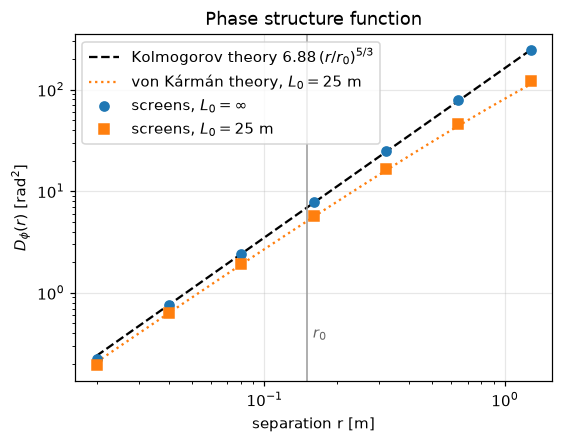

separation   screens/theory (L0 = inf)   screens/theory (L0 = 25 m)
  0.02 m                 0.94                       0.93
  0.04 m                 0.99                       0.99
  0.08 m                 1.01                       1.01
  0.16 m                 1.02                       1.03
  0.32 m                 1.02                       1.04
  0.64 m                 1.02                       1.06
  1.28 m                 1.01                       1.08


In [5]:
SHEET_N, SHEET_DELTA = 256, 0.02            # 5.12 m sheets
separations_px = np.array([1, 2, 4, 8, 16, 32, 64])
r = separations_px * SHEET_DELTA


def structure_function(outer_scale, n_sheets=40):
    d = np.zeros(len(separations_px))
    for seed in range(n_sheets):
        sheet, *_ = fourier_phase_screen(N=SHEET_N, delta=SHEET_DELTA, r0=R0, L0=outer_scale, diameter=None, seed=100 + seed)
        for i, n in enumerate(separations_px):
            d[i] += 0.5 * (np.mean((sheet[:, n:] - sheet[:, :-n]) ** 2) + np.mean((sheet[n:, :] - sheet[:-n, :]) ** 2))
    return d / n_sheets


d_kolmogorov = structure_function(None)
d_von_karman = structure_function(L0)
d_theory = 6.88 * (r / R0) ** (5 / 3)
r_fine = np.logspace(np.log10(r[0]), np.log10(r[-1]), 60)

fig, ax = plt.subplots(figsize=(5.6, 4.1))
ax.loglog(r_fine, 6.88 * (r_fine / R0) ** (5 / 3), "k--", label=r"Kolmogorov theory $6.88\,(r/r_0)^{5/3}$")
ax.loglog(r_fine, von_karman_structure_function(r_fine, R0, L0), ":", color="C1", label=fr"von Kármán theory, $L_0 = {L0:.0f}$ m")
ax.loglog(r, d_kolmogorov, "o", color="C0", label=r"screens, $L_0 = \infty$")
ax.loglog(r, d_von_karman, "s", color="C1", label=fr"screens, $L_0 = {L0:.0f}$ m")
ax.axvline(R0, color="0.6", lw=1)
ax.text(R0 * 1.06, d_theory[0] * 1.5, r"$r_0$", color="0.4")
ax.set(xlabel="separation r [m]", ylabel=r"$D_\phi(r)$ [rad$^2$]", title="Phase structure function")
ax.legend(loc="upper left")
fig.savefig(FIGURES / "01_structure_function.png", dpi=150, bbox_inches="tight")
plt.show()

d_von_karman_theory = von_karman_structure_function(r, R0, L0)
print("separation   screens/theory (L0 = inf)   screens/theory (L0 = 25 m)")
for ri, dk, tk, dv, tv in zip(r, d_kolmogorov, d_theory, d_von_karman, d_von_karman_theory):
    print(f"{ri:6.2f} m {dk / tk:20.2f} {dv / tv:26.2f}")

## 5. Frozen flow

Over a few milliseconds the turbulence keeps its shape and the wind carries it across the pupil (Taylor's hypothesis). `frozen_flow_shift` returns the pupil-sized window of a larger sheet after the turbulence has moved, and refuses to leave the sheet rather than wrapping around.

10 m/s at 1000 Hz moves the screen 0.64 px per frame


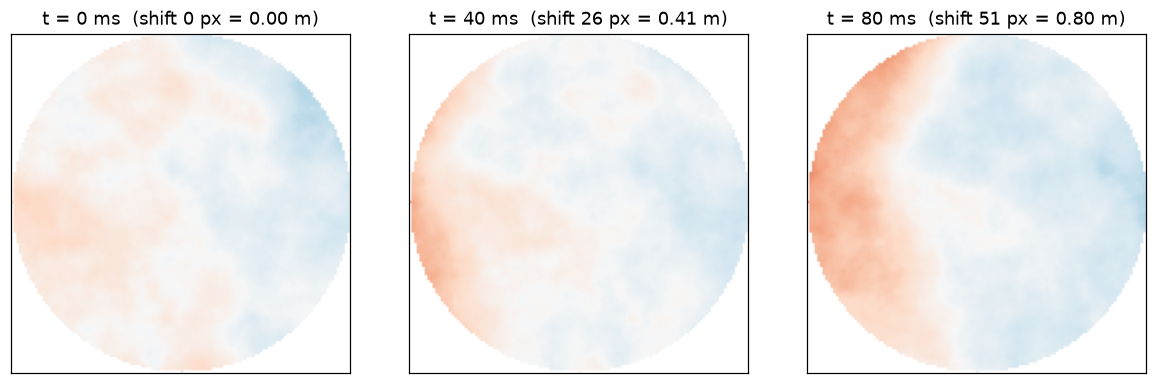

In [6]:
WIND = 10.0           # m/s along x
FRAME_RATE = 1000.0   # Hz
print(f"{WIND:.0f} m/s at {FRAME_RATE:.0f} Hz moves the screen {WIND / FRAME_RATE / DELTA:.2f} px per frame")

sheet, *_ = fourier_phase_screen(N=3 * N, delta=DELTA, r0=R0, L0=L0, diameter=None, seed=7)
_, _, pupil = pupil_grid(N, DELTA, D)
limit = np.percentile(np.abs(sheet), 99)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
for ax, t_ms in zip(axes, [0, 40, 80]):
    shift = int(round(WIND * t_ms * 1e-3 / DELTA))
    window = frozen_flow_shift(sheet, shift, 0, mask=pupil)
    ax.imshow(window, origin="lower", cmap="RdBu_r", vmin=-limit, vmax=limit)
    ax.set_title(f"t = {t_ms} ms  (shift {shift} px = {shift * DELTA:.2f} m)")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
plt.tight_layout()
plt.show()

## Summary

- 0.8″ seeing means $r_0 = 0.13$ m at 500 nm but 0.53 m in H band: for an 8 m telescope $D/r_0$ drops from 63 to 15.
- The screens reproduce the theoretical aperture variance (36.2 ± 1.9 against 36.9 rad²) and both structure functions to within 8%. Without the subharmonics the variance would be three times too low.
- About 73% of the phase variance is tip/tilt for this 2 m pupil, even with a 25 m outer scale.
- At 10 m/s and 1 kHz the turbulence moves 1 cm per frame; the loop in notebook 05 has to keep up with that.